In [97]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC
from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

In [84]:


data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target  # 0 = Maligne, 1 = Bénigne


In [85]:
df.shape
print(df.head(3))
print(df.tail(3))
df.info()

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38           122.8     1001.0          0.11840   
1        20.57         17.77           132.9     1326.0          0.08474   
2        19.69         21.25           130.0     1203.0          0.10960   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0                 0.07871  ...          17.33            184.6      2019.0   
1                 0.05667  ...          23.41            158.8      1956.0   
2                 0.05999  ...          25.53            152.5      1709.0   

   worst smoothness  worst compactness  worst concavity  worst concave points  \


In [86]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
print("Variables numériques")
print(numerical_cols)
print("Variables catégorielles")
print(categorical_cols)



Variables numériques
Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='object')
Variables catégorielles
Index([], dtype='object')


In [87]:

# Pas de colonne 'id' dans le dataset Breast Cancer
# df = df.drop(['id'], axis=1)  # non nécessaire ici


In [88]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [89]:

print(df['target'].unique())  


[0 1]


In [90]:
df[df.duplicated()].sum()

mean radius                0.0
mean texture               0.0
mean perimeter             0.0
mean area                  0.0
mean smoothness            0.0
mean compactness           0.0
mean concavity             0.0
mean concave points        0.0
mean symmetry              0.0
mean fractal dimension     0.0
radius error               0.0
texture error              0.0
perimeter error            0.0
area error                 0.0
smoothness error           0.0
compactness error          0.0
concavity error            0.0
concave points error       0.0
symmetry error             0.0
fractal dimension error    0.0
worst radius               0.0
worst texture              0.0
worst perimeter            0.0
worst area                 0.0
worst smoothness           0.0
worst compactness          0.0
worst concavity            0.0
worst concave points       0.0
worst symmetry             0.0
worst fractal dimension    0.0
target                     0.0
dtype: float64

In [91]:
df.isnull().values.sum()

np.int64(0)

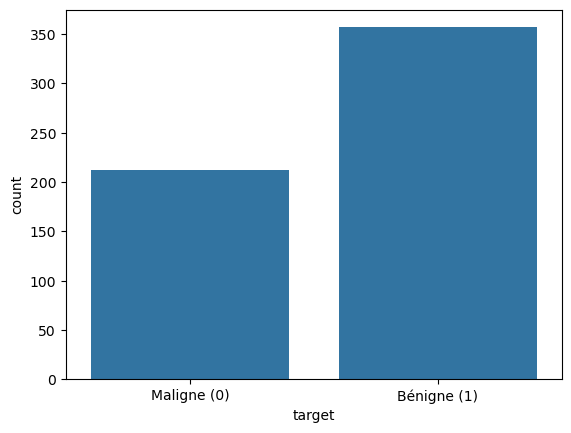

In [92]:

sns.countplot(data=df, x='target')
plt.xticks([0, 1], ['Maligne (0)', 'Bénigne (1)'])
plt.show();


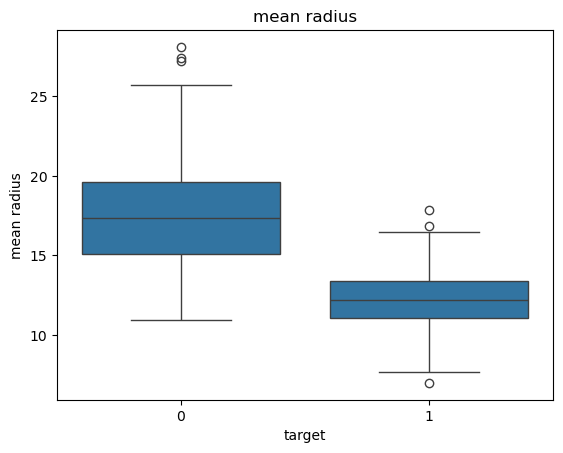

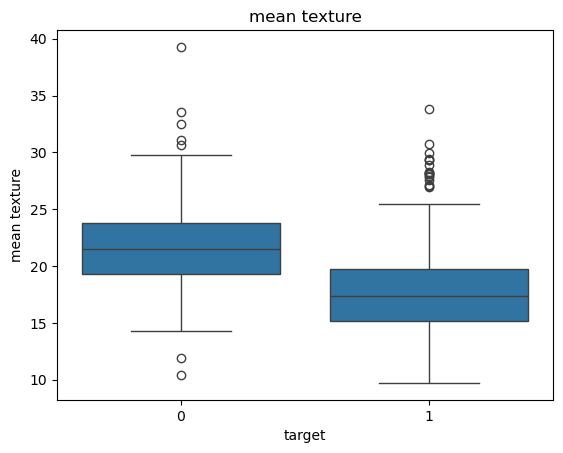

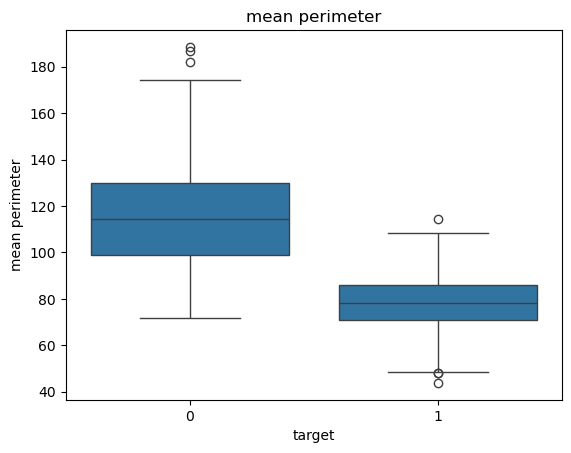

In [93]:

cols = df.columns[:3]

# Boucle simple
for col in cols:
    sns.boxplot(x=df['target'], y=df[col])
    plt.title(col)
    plt.show()


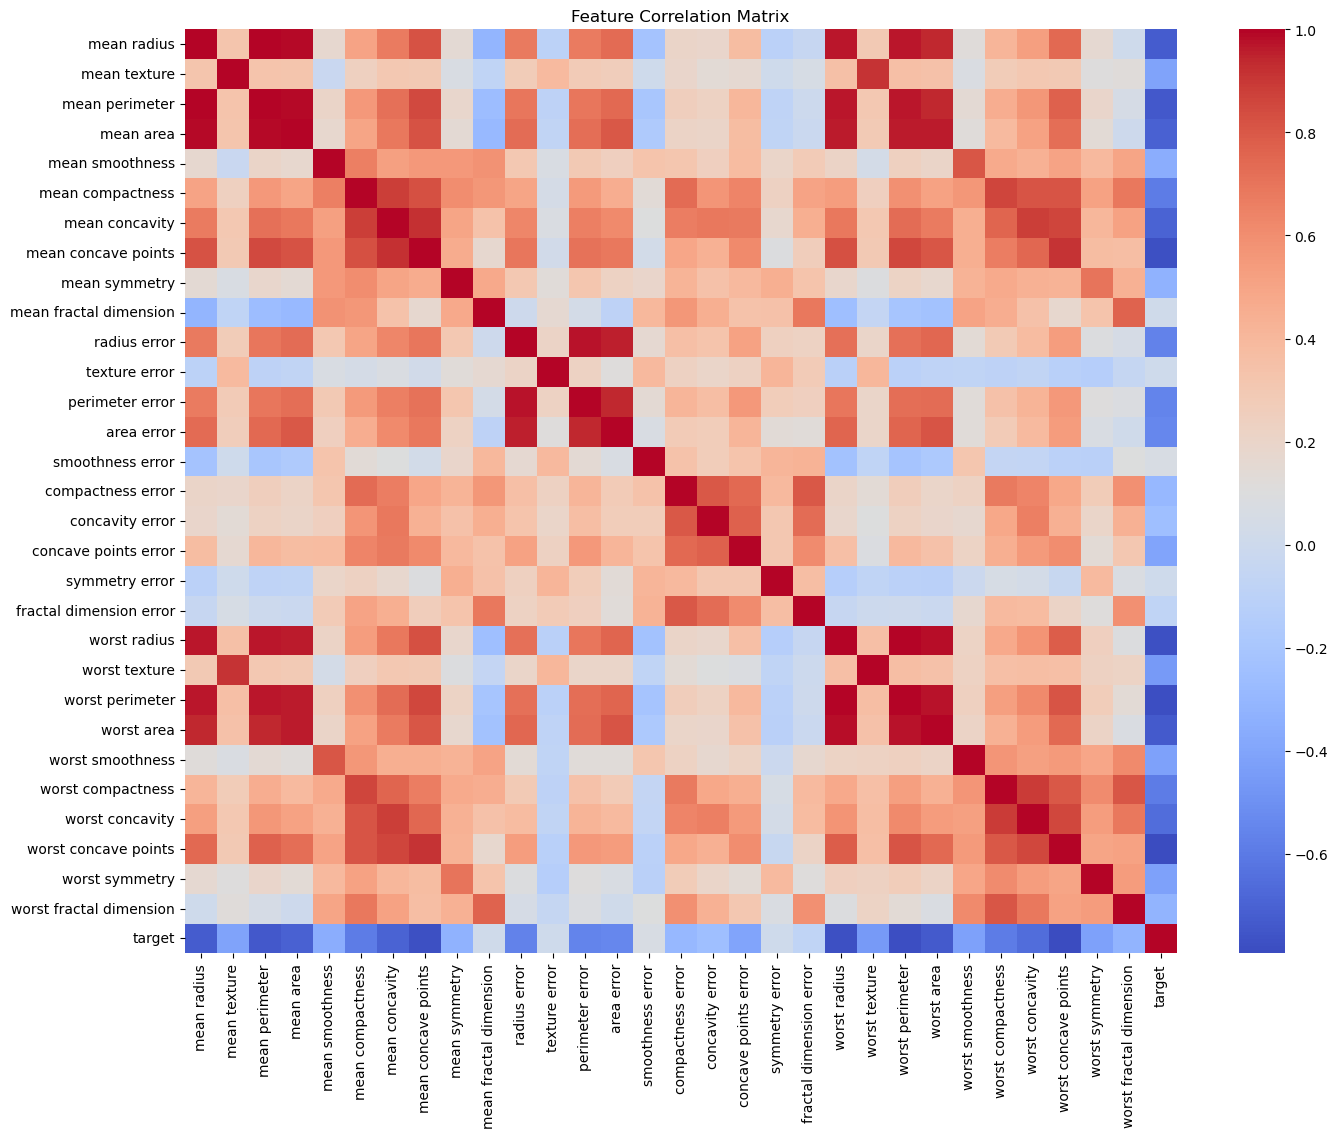

In [94]:
# Plotting a correlation matrix
correlation_matrix = df.corr()

# Display the correlation matrix as a heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Feature Correlation Matrix")
plt.show();

In [108]:

y = df.loc[:, 'target']   # Variable cible (0 = Maligne, 1 = Bénigne)
X = df.loc[:, df.columns !='targe']  # Variables explicatives

print("Variable cible (y) :")
print(y.head())

print("\nVariables explicatives (X) :")
print(X.head())
# # deuxieme methode pour séparer variable explicative et cible
# X = df.drop(columns=['target'])
#  y = df["target"]


Variable cible (y) :
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

Variables explicatives (X) :
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.1043

In [ ]:

seed = 42
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                           
                                                random_state = seed)
print('Taille train :', X_train.shape[0])
print('Taille test  :', X_test.shape[0])

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [ ]:

rf = RandomForestClassifier(random_state = seed)


rf.fit(X_train, y_train)


y_pred = rf.predict(X_test)

In [ ]:
cv_rf = cross_val_score(rf, X, y, cv=5, scoring='accuracy')

print('Scores Cross-Validation :', cv_rf)
print('Moyenne :', round(cv_rf.mean(), 4))
print('Ecart-type :', round(cv_rf.std(), 4))

In [ ]:

accuracy_rf = accuracy_score(y_test, y_pred)
print(f"Random Forest Classifier Accuracy: {accuracy_rf:.4f}")
importances_rf = pd.Series(rf.feature_importances_, index = X.columns)
sorted_importances_rf = importances_rf.sort_values()
sorted_importances_rf.plot(kind='barh', color='lightgreen'); plt.show()

In [ ]:

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))

In [ ]:
# Getting the predicted probabilities for the positive class
y_probs = rf.predict_proba(X_test)[:, 1]

# Computing ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_probs)

# Calculating the AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

# Plotting ROC curve
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label='ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show();

In [ ]:

# Prédiction sur l'ensemble de test
y_pred = rf.predict(X_test)

# Calcul de la matrice de confusion
cm = confusion_matrix(y_test, y_pred)

# Affichage de la matrice de confusion
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Maligne', 'Bénigne'],
            yticklabels=['Maligne', 'Bénigne'])
plt.title('Confusion Matrix')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()


In [ ]:
# Training accuracy
train_accuracy = accuracy_score(y_train, rf.predict(X_train))

# Testing accuracy
test_accuracy = accuracy_score(y_test, y_pred)

# Plotting Train Accuracy vs Test Accuracy
plt.figure(figsize=(6, 4))
accuracy_values = [train_accuracy, test_accuracy]
accuracy_labels = ['Train Accuracy', 'Test Accuracy']

plt.bar(accuracy_labels, accuracy_values, color=['blue', 'orange'])
plt.ylabel('Accuracy')
plt.title('Train Accuracy vs Test Accuracy')
plt.ylim(0, 1)
plt.show();

In [ ]:
para_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

svm = SVC(probability=True)
grid = GridSearchCV(
    svm,
    para_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)
print("Meilleurs para SVM :", grid.best_params_)
best_svm = grid.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)


In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1-score:", f1_score(y_test, y_pred_svm))

In [ ]:
cm = confusion_matrix(y_test, y_pred_svm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Matrice de confusion - SVM")
plt.show()


In [ ]:
y_probs_svm = best_svm.predict_proba(X_test_scaled)[:, 1]

# Calcul ROC
fpr, tpr, thresholds = roc_curve(y_test, y_probs_svm)

# AUC
roc_auc = roc_auc_score(y_test, y_probs_svm)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"SVM (AUC = {roc_auc:.3f})")
plt.plot([0,1], [0,1], linestyle='--')  # ligne aléatoire
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")
plt.legend()
plt.grid()
plt.show()

In [ ]:
y_probs_rf = rf.predict_proba(X_test)[:, 1]
y_probs_svm = best_svm.predict_proba(X_test_scaled)[:, 1]

# ROC RF
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_probs_rf)
auc_rf = roc_auc_score(y_test, y_probs_rf)

# ROC SVM
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_probs_svm)
auc_svm = roc_auc_score(y_test, y_probs_svm)

# Plot
plt.figure(figsize=(8,6))

plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC = {auc_svm:.3f})")

# ligne aléatoire
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Comparaison ROC : SVM vs Random Forest")
plt.legend()
plt.grid()

plt.show()